In [89]:
import json
import gzip
import torch
import torch.nn as nn

import numpy as np

from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [8]:
with gzip.open("data/o16_2026-11-26-104215391642.json.gz", "rt") as f:
    data = json.load(f)

with gzip.open("data/header.json.gz", "rt") as f:
    header = json.load(f)

In [95]:
"""
Energies: 296
For each energy, ie data[i]:
    - cn_ex: (float)
    - Angles: 32 (list)
    - c^2: 32 (list)
    - alpha_real: 32 (list)
    - alpha_imag: 32 (list)
    - cstaralpha_real: 32 (list)
    - cstaralpha_imag: 32 (list)
    - tmatrix_real: 6 (list)
    - tmatrix_imag: 6 (list)
    - sigmas: 32 (list) - sigma evaluated at cn_ex, for each 32 angles. 
"""

energies = np.array([row['cn_ex'] for row in data])
sigmas = np.array([row['sigmas'] for row in data])

tmatrix_real = np.array([row['tmatrix_real'] for row in data])
tmatrix_imag = np.array([row['tmatrix_imag'] for row in data])

tmatrix_complex = tmatrix_real + 1j * tmatrix_imag 

c2 = np.array([row['c^2'] for row in data])
alpha = np.array([row['alpha_real'] for row in data]) + 1j * np.array([row['alpha_imag'] for row in data])

cstaralpha = np.array([row['cstaralpha_real'] for row in data ]) + 1j * np.array([row['cstaralpha_imag'] for row in data])

print(tmatrix_complex.shape)
print(c2.shape)
print(alpha.shape)
print(cstaralpha.shape)

(296, 6)
(296, 32)
(296, 32, 6)
(296, 32, 6)


In [97]:
split_indices = np.arange(len(energies))

train_indices, testval_indices = train_test_split(
    split_indices, test_size = 0.3, random_state=1
)

val_indices, test_indices = train_test_split(
    testval_indices, test_size = 0.5, random_state=1
)

In [98]:
sigmas_train = sigmas[train_indices]
alpha_train = alpha[train_indices]
c2_train = c2[train_indices]
cstaralpha_train = cstaralpha[train_indices]

sigmas_val = sigmas[val_indices]
alpha_val = alpha[val_indices]
c2_val = c2[val_indices]
cstaralpha_val = cstaralpha[val_indices]

sigmas_test = sigmas[test_indices]
alpha_test = alpha[test_indices]
c2_test = c2[test_indices]
cstaralpha_test = cstaralpha[test_indices]

Split dataset into training, validation and testing 

Standardise the T values in training so squared errors contribute equally
Standardise energies so optimisation is easier 

In [105]:
X = energies.reshape(-1, 1)
X_train = X[train_indices]
X_val = X[val_indices]
X_test = X[test_indices]

X_standardised = StandardScaler()
Y_standardised = StandardScaler()

X_train_scaled = X_standardised.fit_transform(X_train)
X_val_scaled = X_standardised.transform(X_val)
X_test_scaled = X_standardised.transform(X_test)

In [106]:
print(X_train_scaled.mean())
print(X_train_scaled.std())

-1.1520575154081334e-15
1.0


In [ ]:
X_train_tensor = torch.tensor(X_train_scaled, dtype = torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)


sigmas_train_tensor = torch.tensor(sigmas_train, dtype=torch.float32)
sigmas_val_tensor = torch.tensor(sigmas_val, dtype=torch.float32)
sigmas_test_tensor = torch.tensor(sigmas_test, dtype=torch.float32)

alpha_train_tensor = torch.tensor(alpha_train, dtype=torch.float32)
alpha_val_tensor = torch.tensor(alpha_val, dtype=torch.float32)
alpha_test_tensor = torch.tensor(alpha_test, dtype=torch.float32)

c2_train_tensor = torch.tensor(c2_train, dtype=torch.float32)
c2_val_tensor = torch.tensor(c2_val, dtype=torch.float32)
c2_test_tensor = torch.tensor(c2_test, dtype=torch.float32)

cstaralpha_train_tensor = torch.tensor(cstaralpha_train, dtype=torch.float32)
cstaralpha_val_tensor = torch.tensor(cstaralpha_val, dtype=torch.float32)
cstaralpha_test_tensor = torch.tensor(cstaralpha_test, dtype=torch.float32)

Model Architecture:

In [90]:
torch.manual_seed(1)

model = nn.Sequential(
    nn.Linear(1, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 12)
)

print(model)

Sequential(
  (0): Linear(in_features=1, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=12, bias=True)
)


In [104]:
prediction = model(X_train_tensor)
real_parts = prediction[:, :6]
imag_parts = prediction[:, 6:]

T_pred = torch.complex(real_parts, imag_parts)
print(T_pred.shape)

torch.Size([207, 6])


Defining the loss function

# Data Analysis

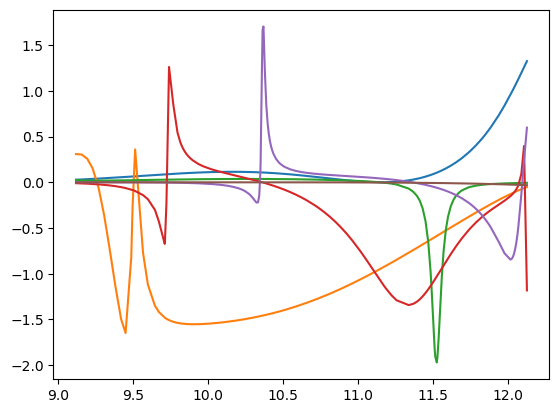

In [49]:
plt.plot(energies, tmatrix_real)
plt.show()

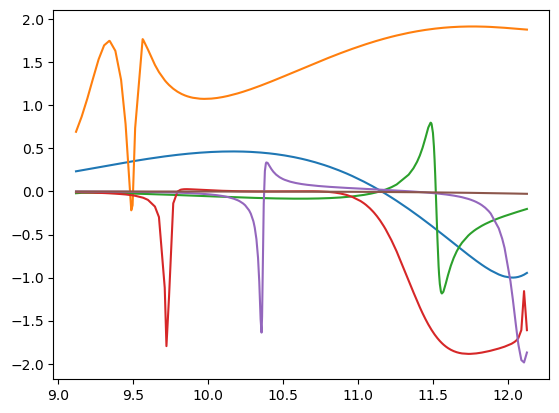

In [50]:
plt.plot(energies, tmatrix_imag)
plt.show()

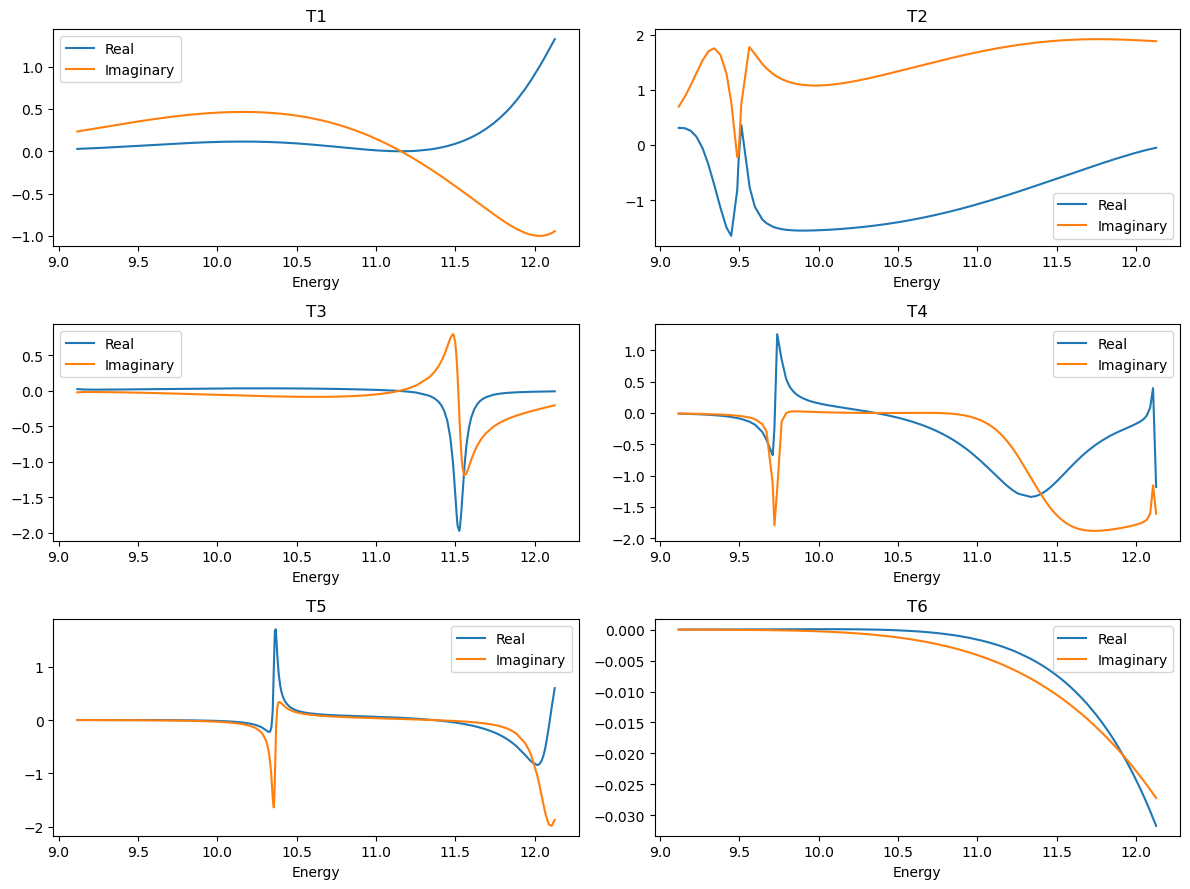

In [51]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9))

for j, ax in enumerate(axes.flat):
    ax.plot(energies, tmatrix_real[:, j], label="Real")
    ax.plot(energies, tmatrix_imag[:, j], label="Imaginary")
    ax.set_title(f"T{j+1}")
    ax.set_xlabel("Energy")
    ax.legend()

plt.tight_layout()
plt.show()